#### Fashion MNIST

In [40]:
# # # function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [41]:
# # function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
import importlib
import multiclass_functions
importlib.reload(multiclass_functions)

from multiclass_functions import *
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
# datasets:  이미지 파일과 정답 레이블을 관리하고, 모델 학습에 사용할 수 있는 Dataset 객체를 생성하는 모듈
# transforms: 모델이 학습할 수 있도록 이미지의 크기, 자료형, 차원, 픽셀값 등을 변환하는 모듈입니다. 데이터 증강(Data Augmentation)에도 사용됩니다.
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [42]:
# Kaggle에서 fashionmnist 다운로드
import os
import kagglehub

data_path = os.path.join(os.getcwd(), "data")
raw_path = os.path.join(data_path, "FashionMNIST", "raw")

path = kagglehub.dataset_download(
    "zalando-research/fashionmnist",
    output_dir=raw_path
)

In [43]:
transform = transforms.ToTensor()

train_DS = datasets.FashionMNIST(root=data_path, train=True, transform=transform)
test_DS = datasets.FashionMNIST(root=data_path, train=False, transform=transform)

In [ ]:
BATCH_SIZE = 32
LR = 1e-2
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True

# model_type = 'CNN'    # accuracy= 89.99%
model_type = 'CNN_deep' # accuracy= 
dataset = 'FashionMNIST'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [45]:
train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

In [46]:
print(train_DS)
print(test_DS)
print(test_DS.classes)
print(test_DS.class_to_idx)

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: c:\Users\mega\KYJ\PyTorch\05.CNN\data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: c:\Users\mega\KYJ\PyTorch\05.CNN\data
    Split: Test
    StandardTransform
Transform: ToTensor()
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}


In [47]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

torch.Size([32, 1, 28, 28])


In [48]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1,8,3, padding=1),    # input(32,1,28,28)
            nn.BatchNorm2d(8),
            nn.ReLU()
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU()
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU()
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args,**kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(1,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())

        self.maxpool2 = nn.MaxPool2d(2)
        
        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU())

        self.maxpool3 = nn.MaxPool2d(2) # maxpool도 출력크기는 똑같이 계산(stride 와 kernel에 2를 대입)

        self.fc = nn.Sequential(nn.Linear(128*3*3,512),
                                nn.ReLU(),
                                nn.Linear(512, 10))

    def forward(self, x, *args, **kwargs):
        x = self.conv_block1(x)
        x = self.maxpool1(x)
        x = self.conv_block2(x)
        x = self.maxpool2(x)
        x = self.conv_block3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [49]:
model = globals()[model_type]().to(device)

Epoch : 1, train loss : 0.574
--------------------
Epoch : 2, train loss : 0.332
--------------------
Epoch : 3, train loss : 0.296
--------------------
Epoch : 4, train loss : 0.268
--------------------
Epoch : 5, train loss : 0.245
--------------------
Epoch : 6, train loss : 0.235
--------------------
Epoch : 7, train loss : 0.222
--------------------
Epoch : 8, train loss : 0.209
--------------------
Epoch : 9, train loss : 0.196
--------------------
Epoch : 10, train loss : 0.188
--------------------
Epoch : 11, train loss : 0.180
--------------------
Epoch : 12, train loss : 0.172
--------------------
Epoch : 13, train loss : 0.166
--------------------
Epoch : 14, train loss : 0.156
--------------------
Epoch : 15, train loss : 0.150
--------------------


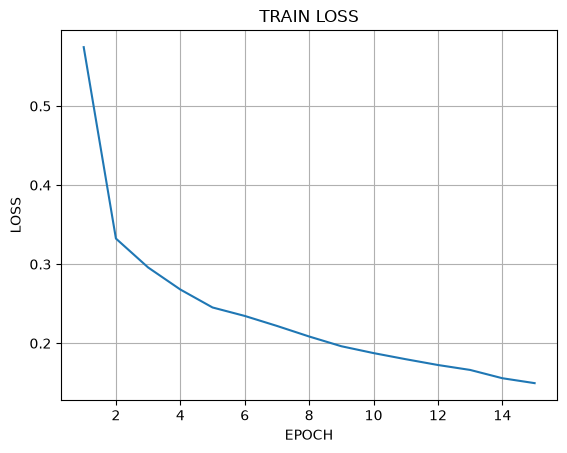

In [50]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('EPOCH')
    plt.ylabel('LOSS')
    plt.title('TRAIN LOSS')
    plt.grid()

In [51]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [52]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 9148 / 10000 (91.5 %)
1067690


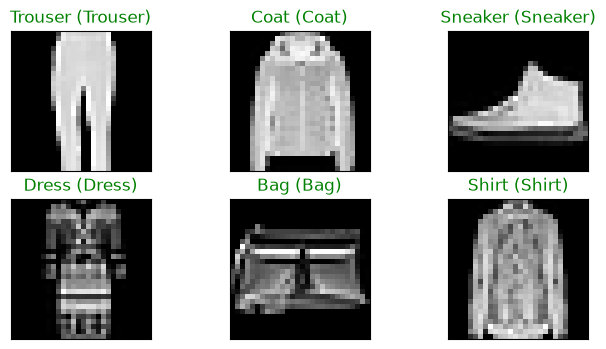

In [53]:
Test_plot(load_model, test_DL)

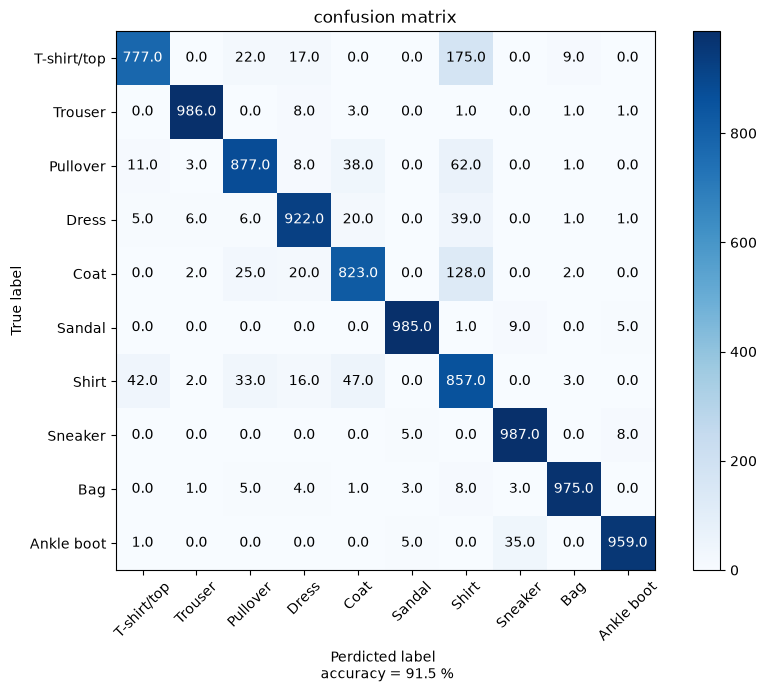

In [54]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

plt.xticks(rotation=45);

torch.Size([32, 32, 28, 28])
torch.Size([32, 64, 14, 14])
torch.Size([32, 128, 7, 7])


Text(0.5, 1.0, 'Sneaker (Sneaker)')

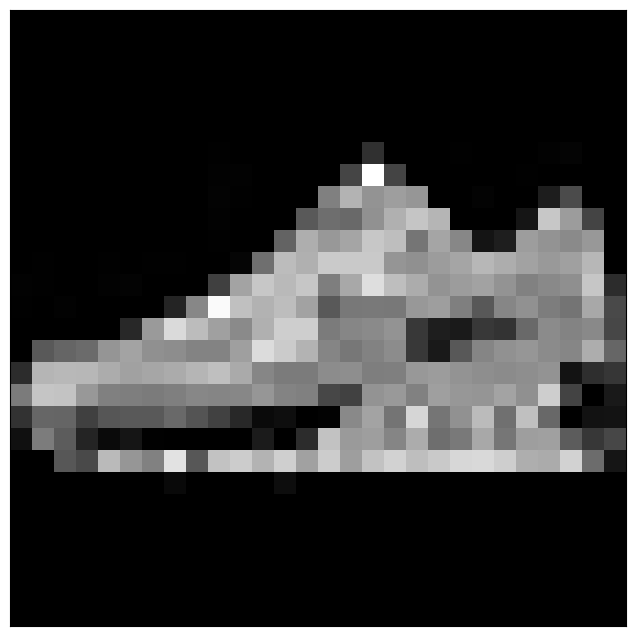

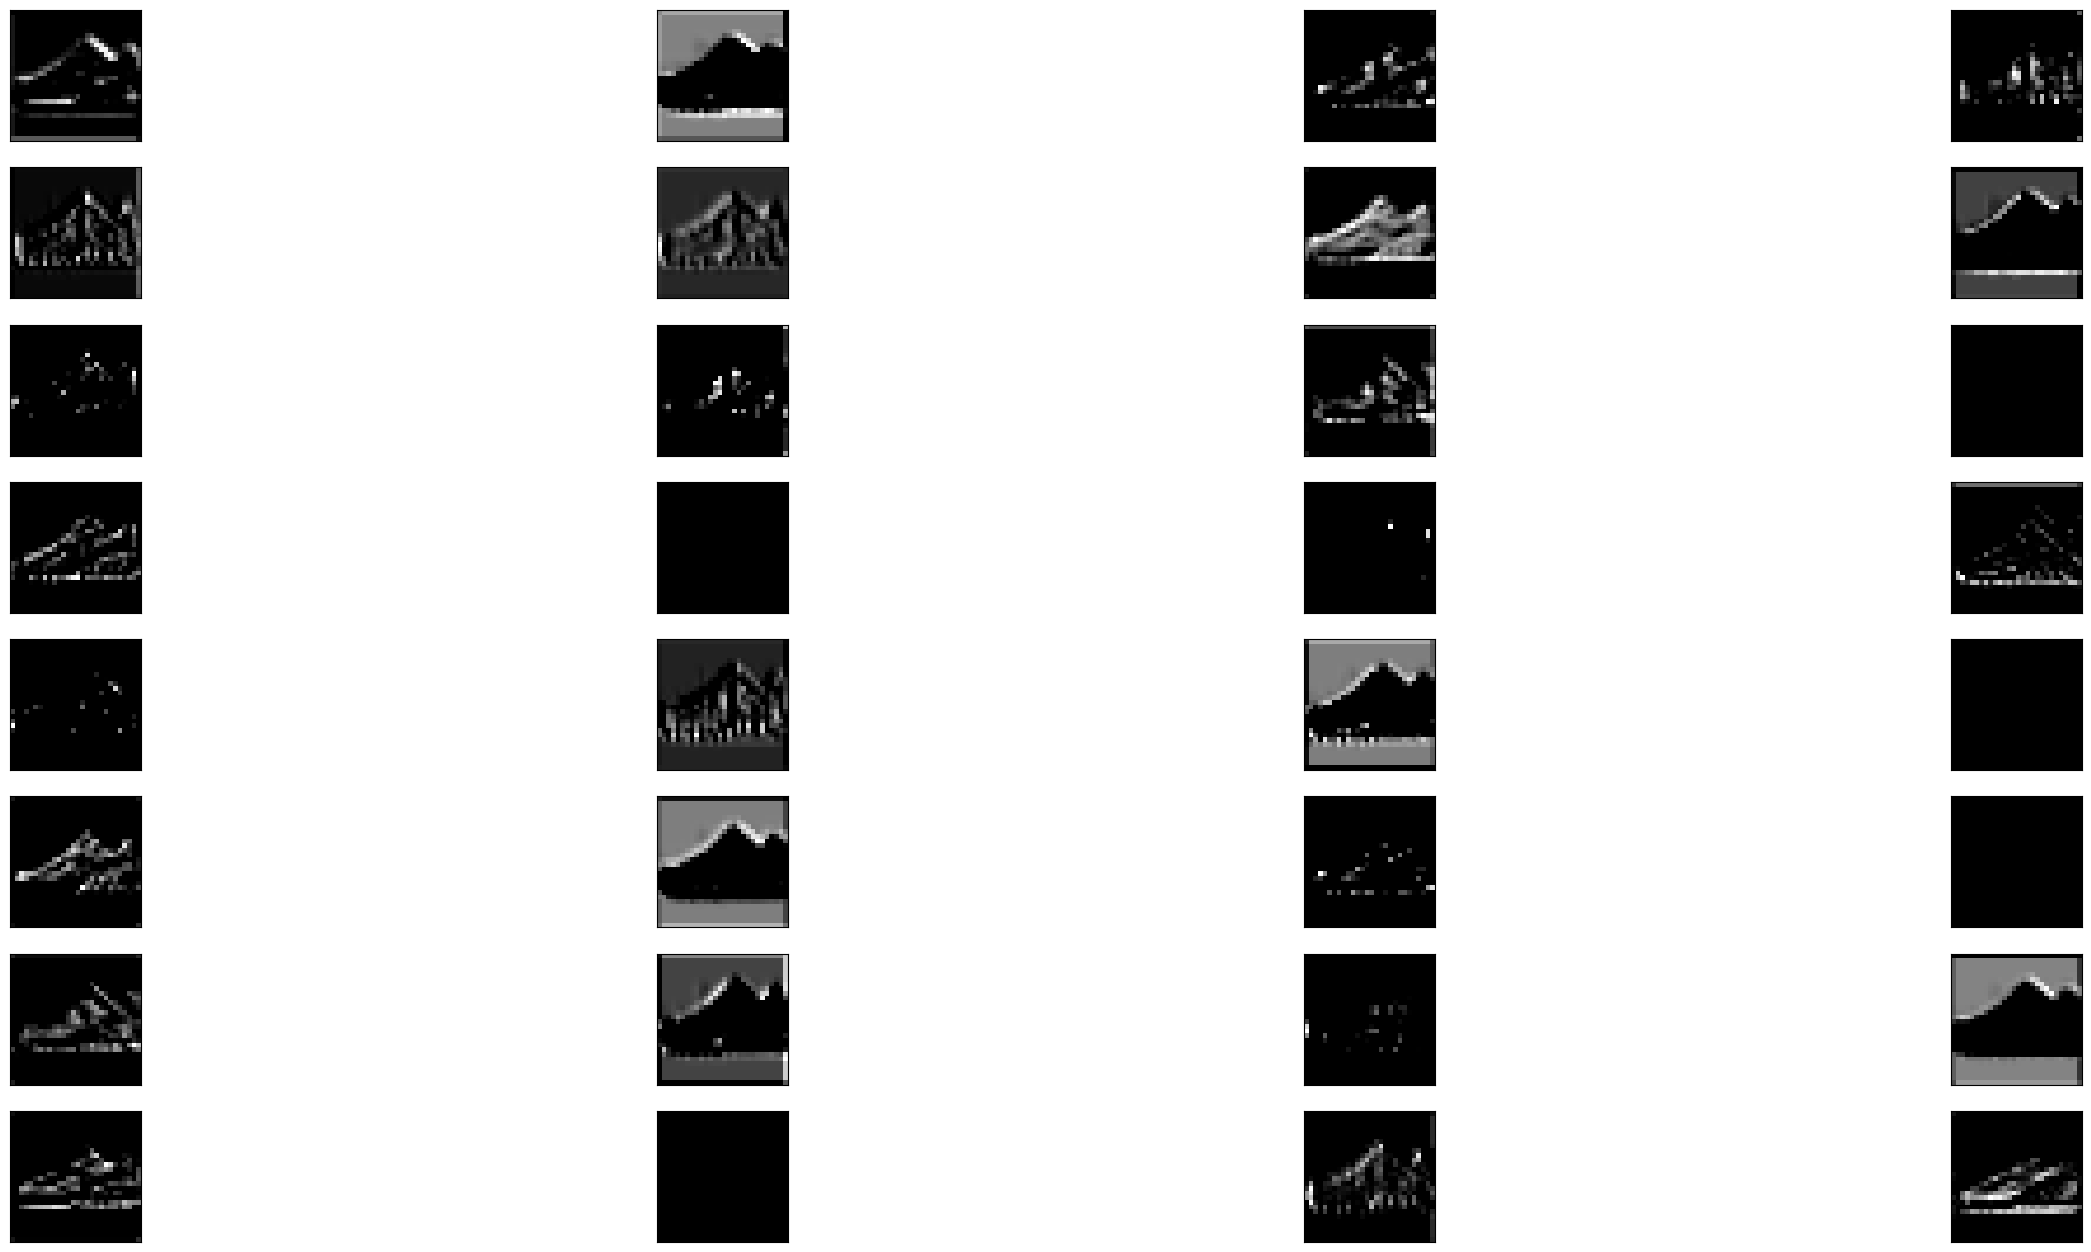

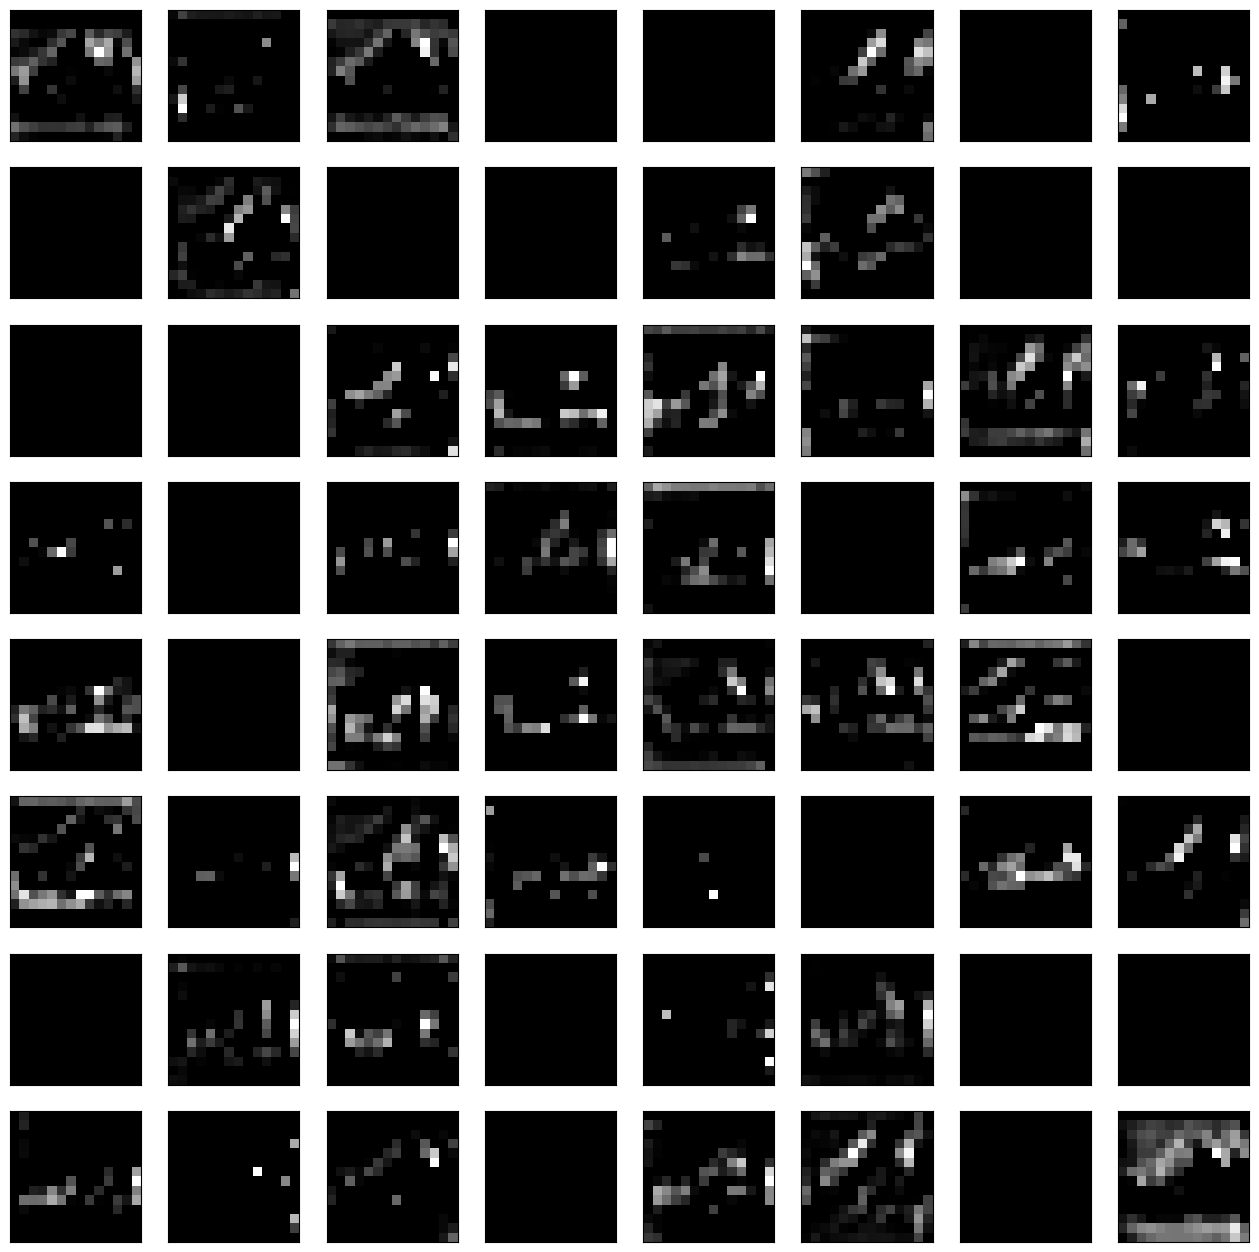

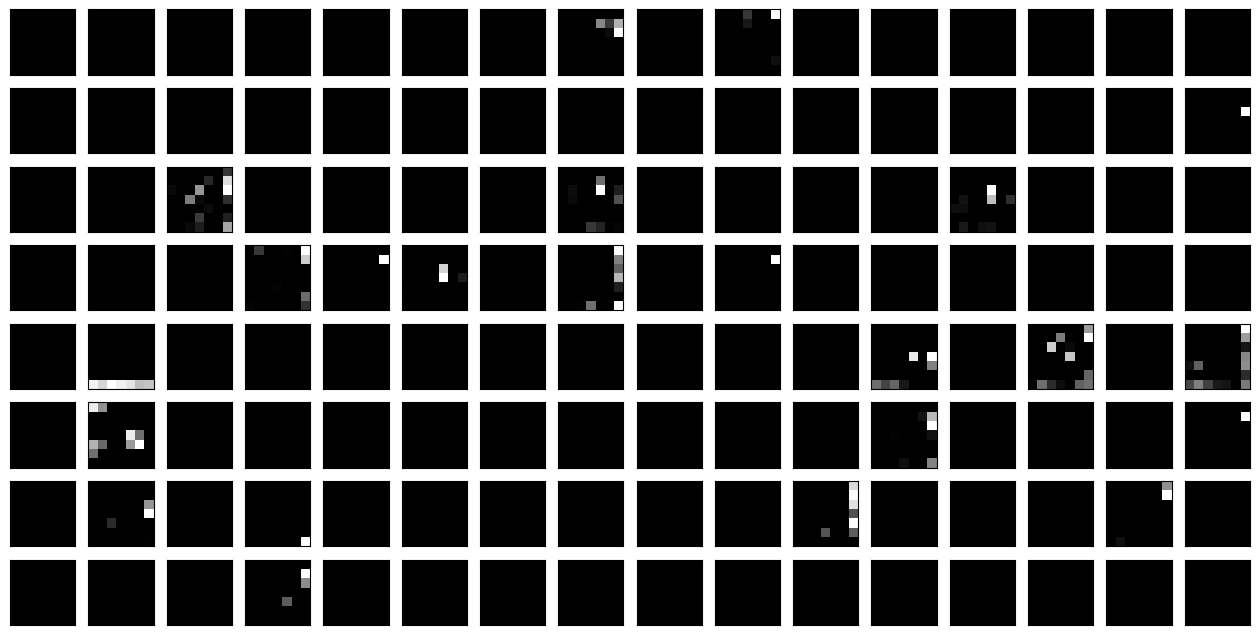

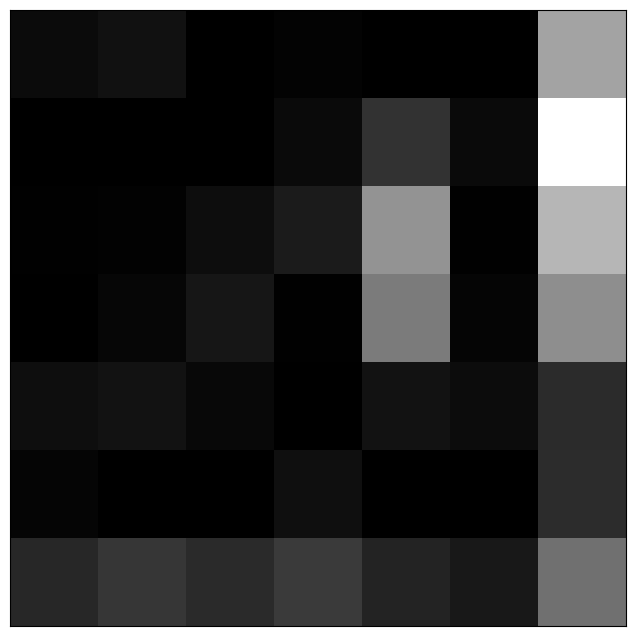

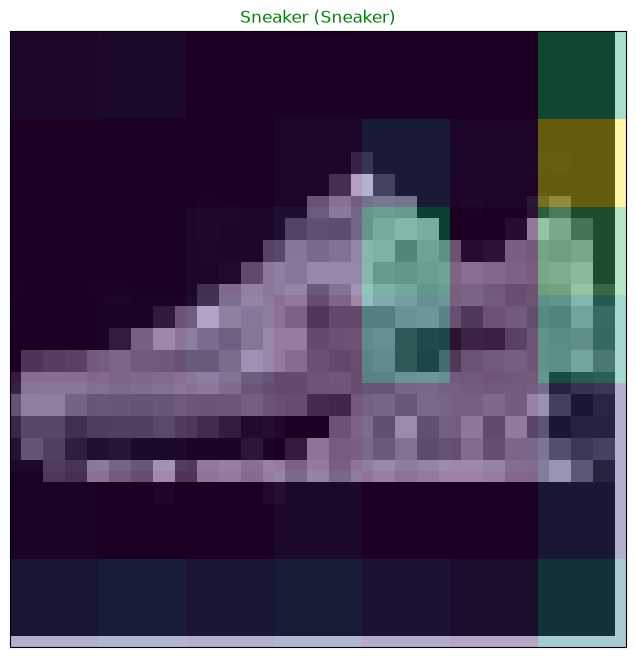

In [55]:
# feature_map : model 의 convolution 이후 틀징을 이미지화
load_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch, y_batch = x_batch.to(device), y_batch.to(device)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    if model_type == 'CNN':
        feature_map1 = load_model.conv1(x_batch)
        feature_map2 = load_model.conv2(load_model.maxpool1(feature_map1))
        feature_map3 = load_model.conv3(load_model.maxpool2(feature_map2))
    
    elif model_type == 'CNN_deep':
        feature_map1 = load_model.conv_block1(x_batch)
        feature_map2 = load_model.conv_block2(load_model.maxpool1(feature_map1))
        feature_map3 = load_model.conv_block3(load_model.maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])  # 눈금표시안함
plt.yticks([])
plt.imshow(x_batch[0,0], cmap= 'gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    # convolution 이후 (32,32,28,28) 중 2번째 차원 특징을 가져오기
    plt.subplot(8,4, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')
    # feature_map1[0,0] 의 특징부터 feature_map[0,31]까지 보여줌

print(feature_map2.shape)
plt.figure(figsize=(16,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summmed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summmed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap='gray')
# convolution 이후의 (3,3)을 (28,28) 사이즈로 맞춤
plt.imshow(summmed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')

pred_item = test_DS.classes[pred[0].item()]
true_item = test_DS.classes[y_batch[0].item()]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')

torch.Size([1, 32, 28, 28])
torch.Size([1, 64, 14, 14])
torch.Size([1, 128, 7, 7])


Text(0.5, 1.0, 'Shirt (Coat)')

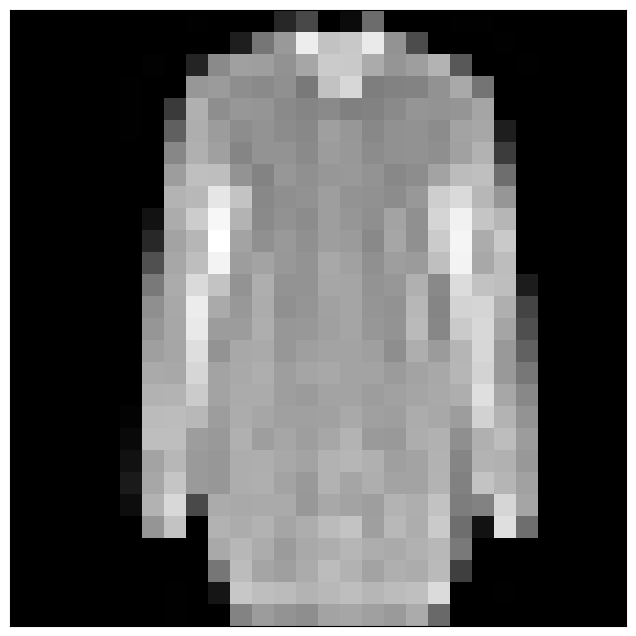

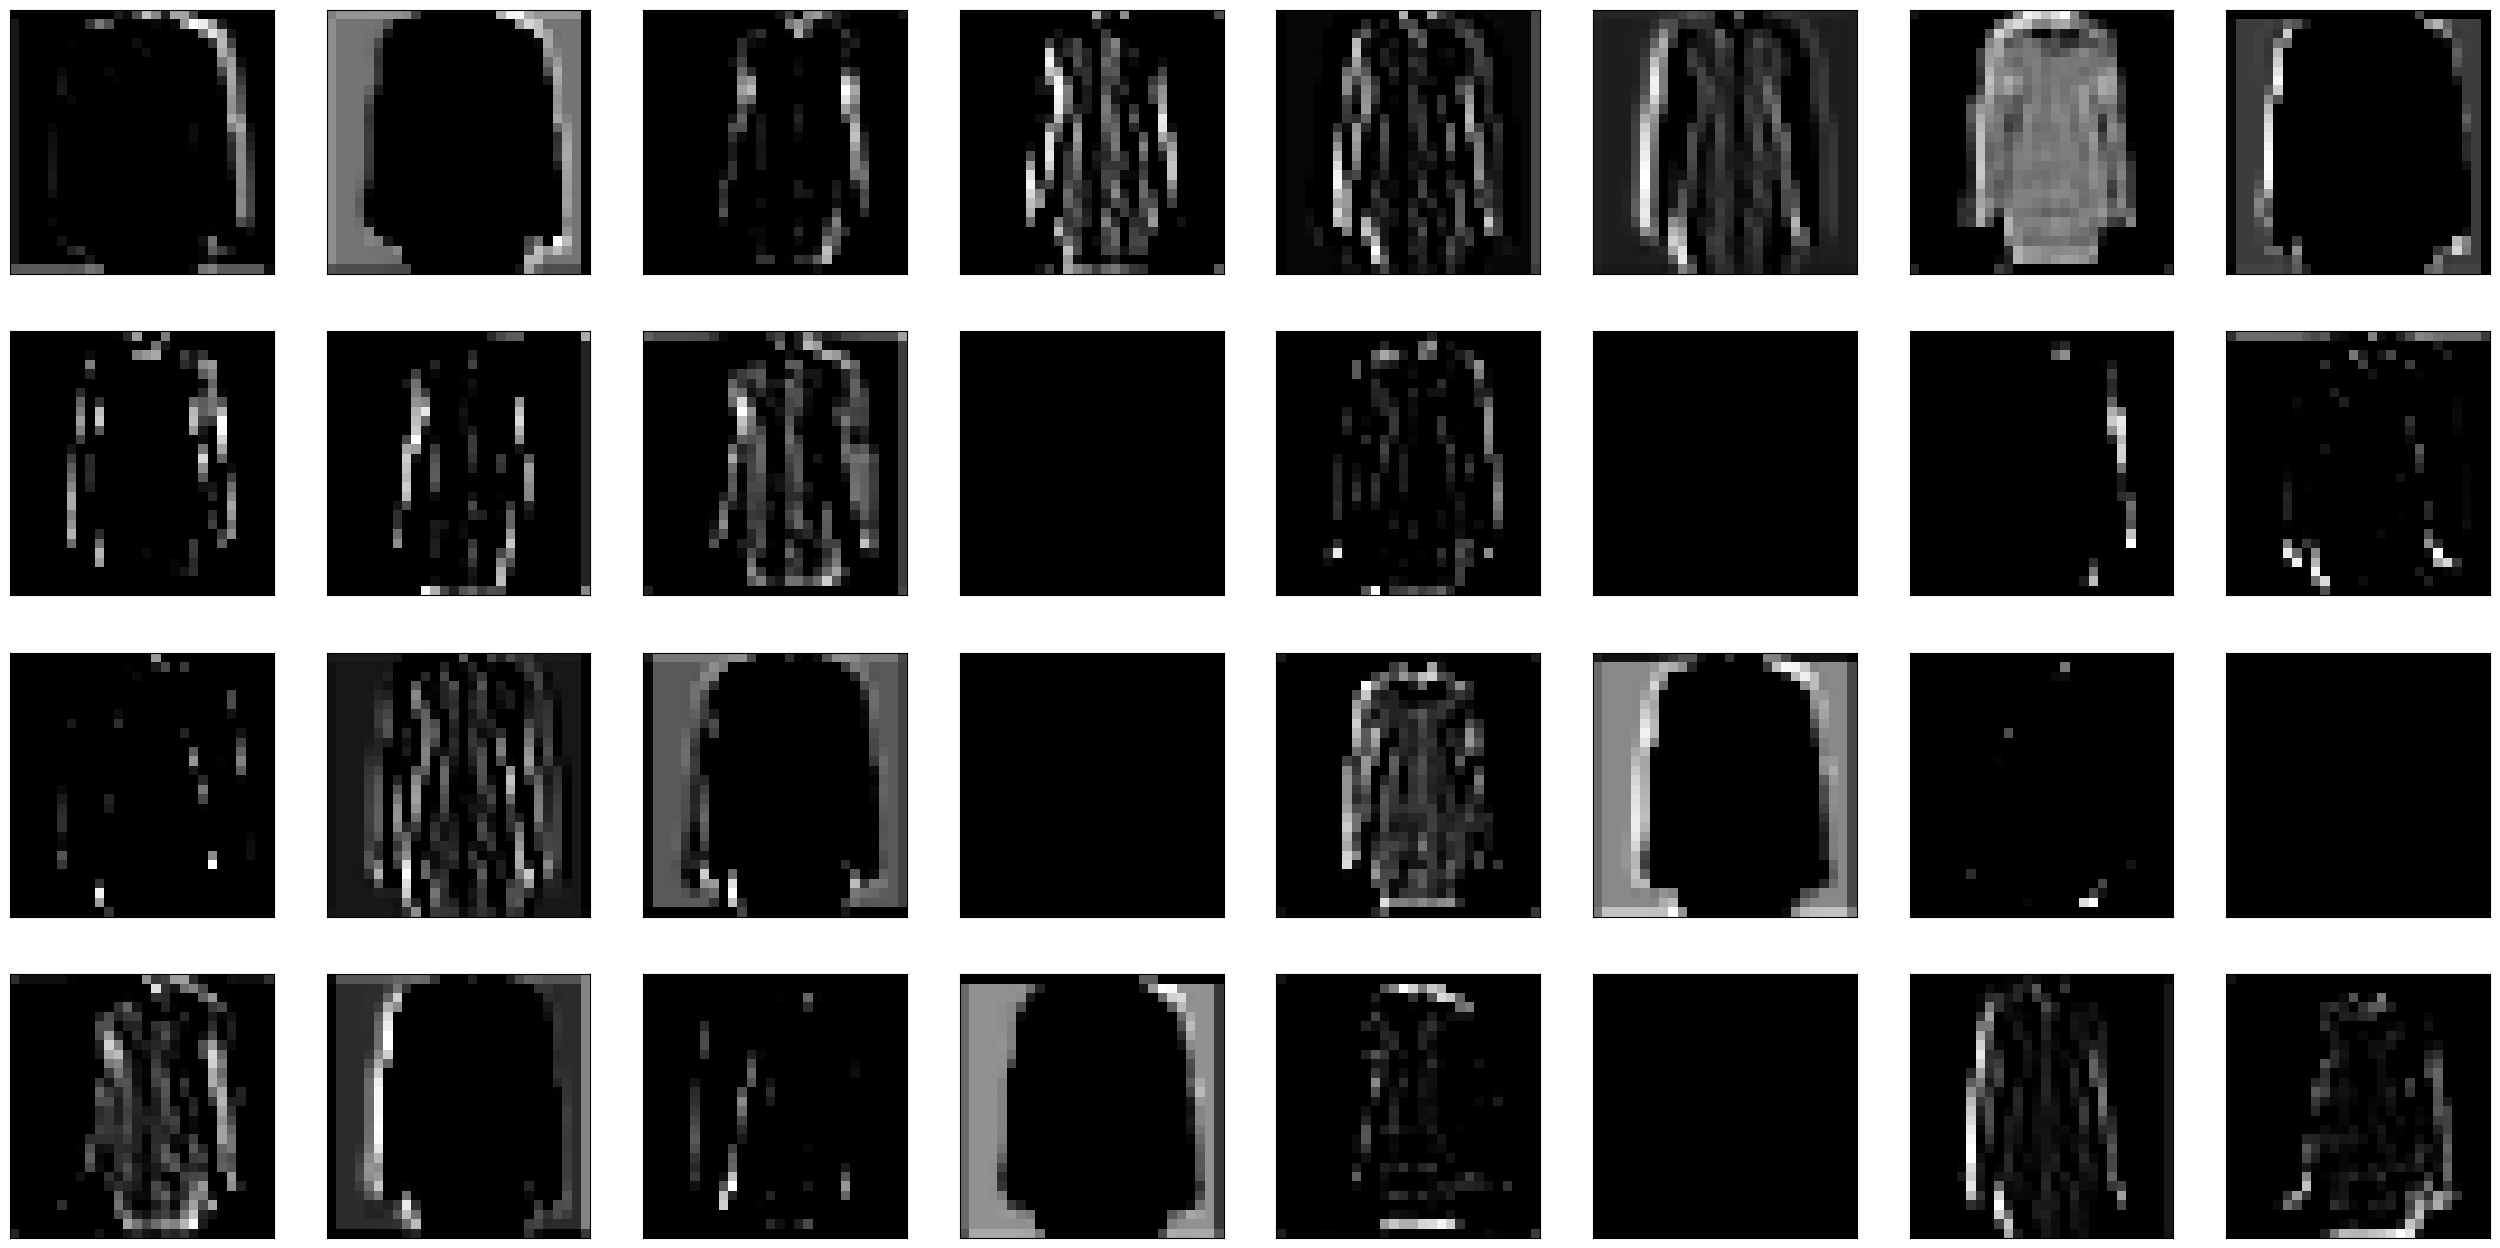

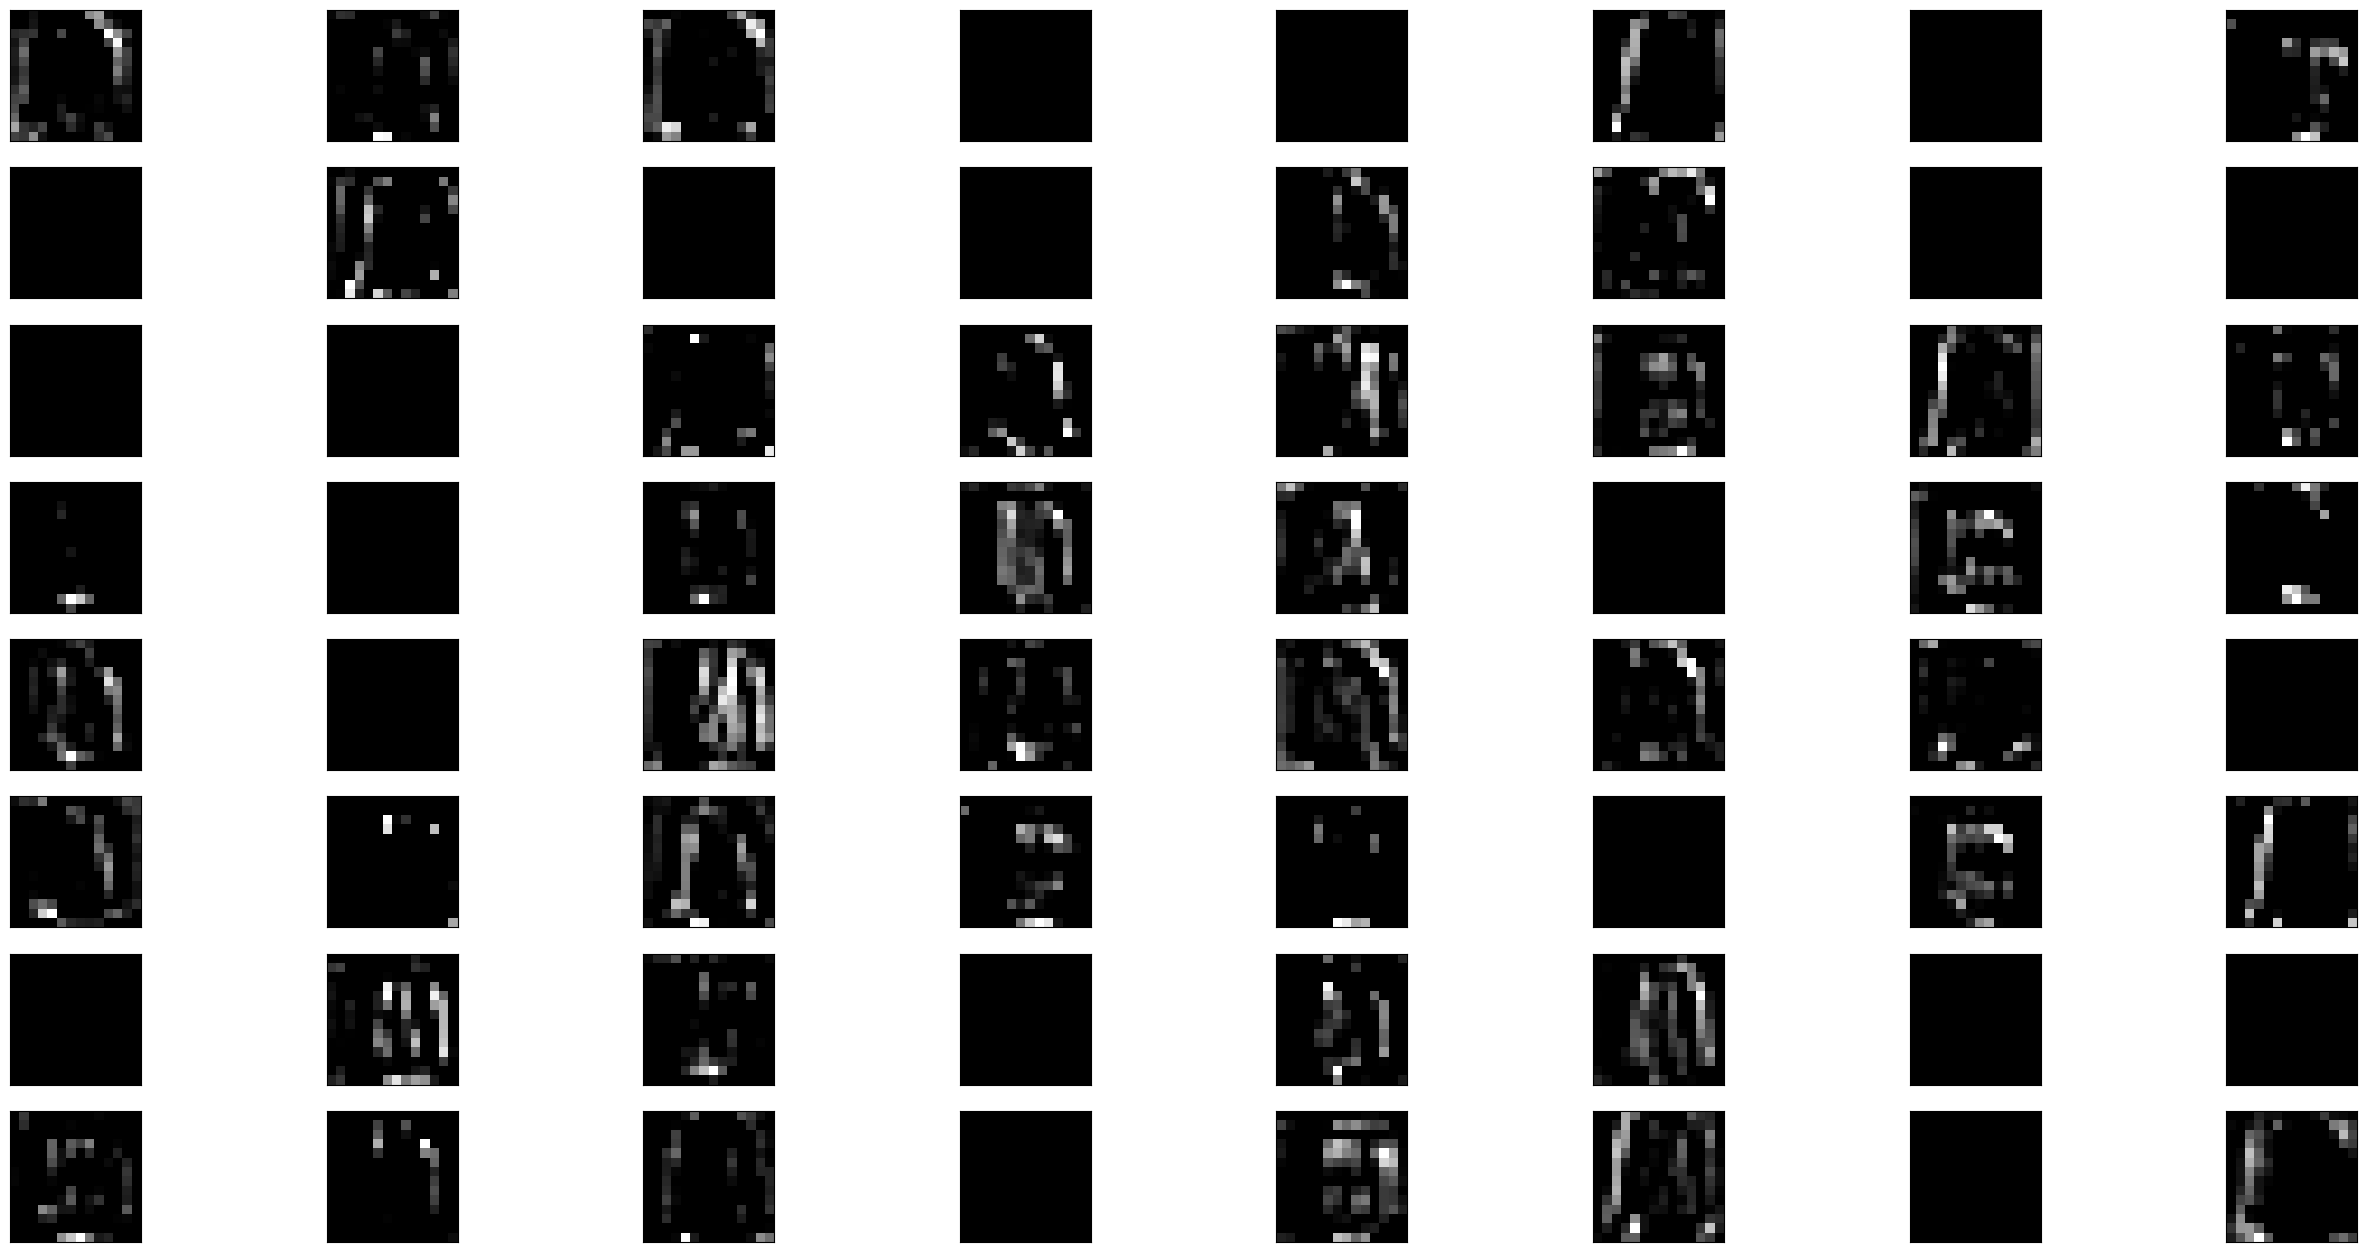

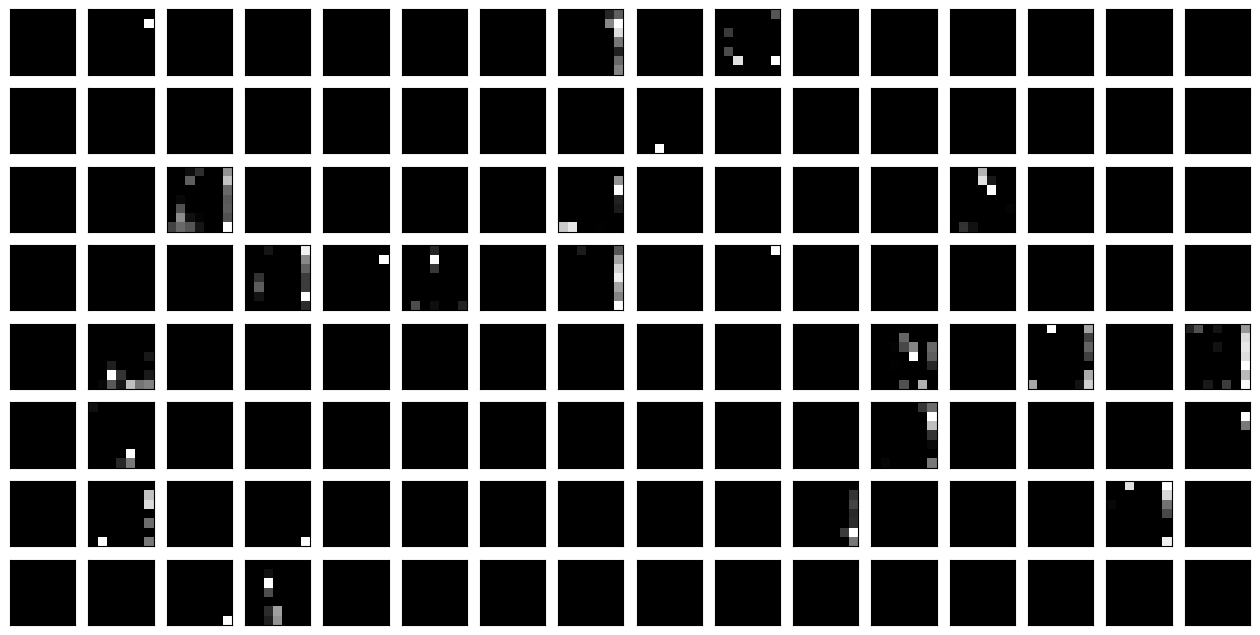

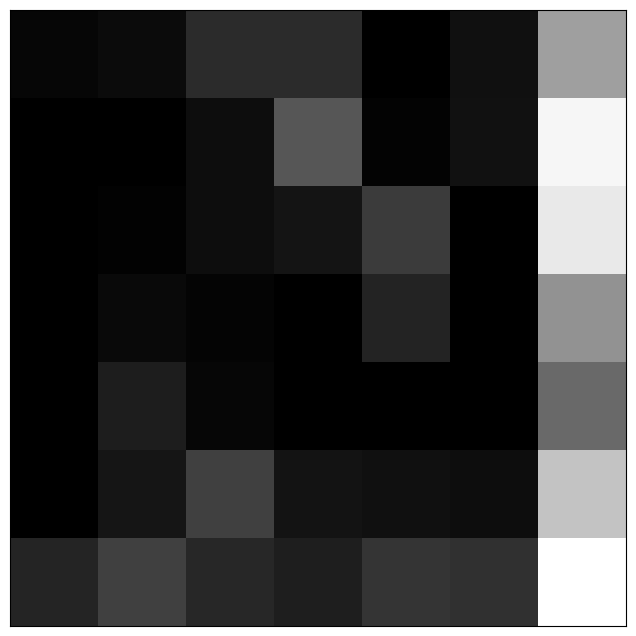

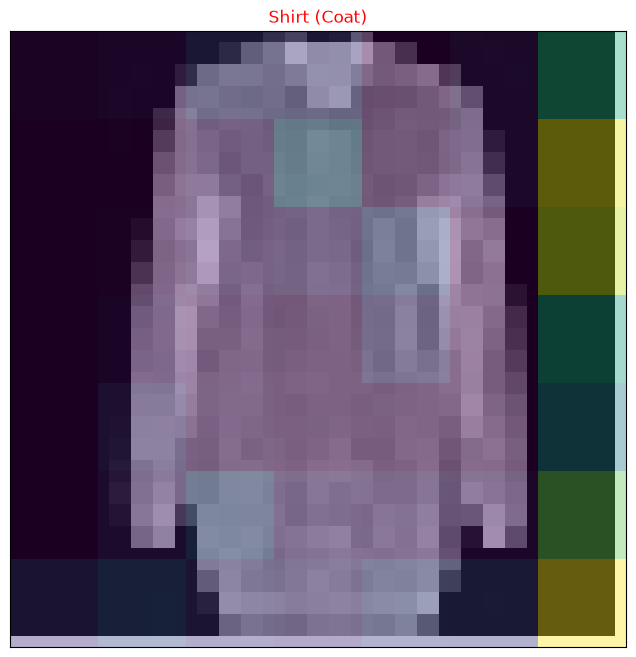

In [56]:
load_model.eval()
with torch.no_grad():
    wrong_image = None

    for x_batch, y_batch in test_DL:
        x_batch, y_batch = next(iter(test_DL))
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        y_hat = load_model(x_batch)
        pred = y_hat.argmax(dim=1)

        wrong_idx = torch.where(pred != y_batch)[0]

        if len(wrong_idx) > 0 :
            idx = wrong_idx[0].item()

            wrong_image = x_batch[idx:idx+1]

            pred_label = pred[idx].item()
            true_label = y_batch[idx].item()

    if wrong_image is not None :

        if model_type == 'CNN':
            feature_map1 = load_model.conv1(wrong_image)
            feature_map2 = load_model.conv2(load_model.maxpool1(feature_map1))
            feature_map3 = load_model.conv3(load_model.maxpool2(feature_map2))

        elif model_type == 'CNN_deep':
            feature_map1 = load_model.conv_block1(wrong_image)
            feature_map2 = load_model.conv_block2(load_model.maxpool1(feature_map1))
            feature_map3 = load_model.conv_block3(load_model.maxpool2(feature_map2))

wrong_image = wrong_image.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred_label]
true_item = test_DS.classes[true_label]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')

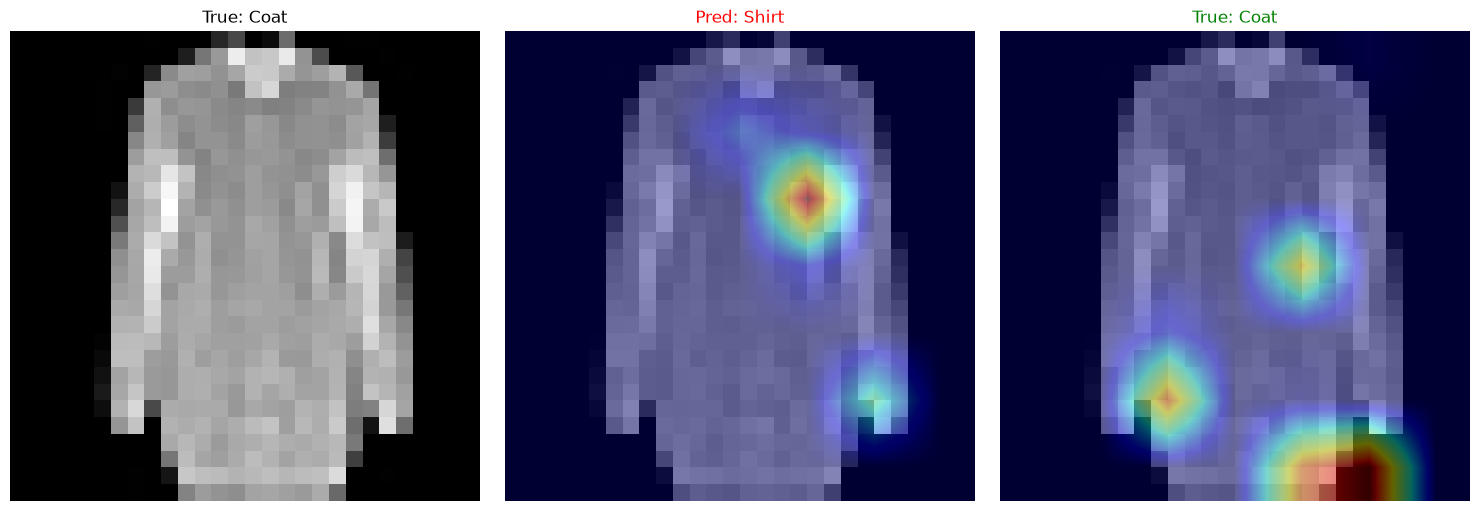

In [57]:
# Grad - CAM

# 모델이 오답이라고 예측한 클래스의 Grad-CAM
pred_cam = get_gradcam(
    load_model,
    wrong_image,
    model_type,
    target_class=pred_label
)

# 실제 정답 클래스의 Grad-CAM
true_cam = get_gradcam(
    load_model,
    wrong_image,
    model_type,
    target_class=true_label
)

image = wrong_image[0, 0].cpu()

plt.figure(figsize=(15, 5))

# 원본 이미지
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title(f'True: {test_DS.classes[true_label]}')
plt.axis('off')

# 예측 클래스 Grad-CAM
plt.subplot(1, 3, 2)
plt.imshow(image, cmap='gray', extent=[0,28,28,0])
plt.imshow(pred_cam, cmap='jet',
           extent=[0,28,28,0],
           alpha=0.4, interpolation='bilinear')
plt.title(f'Pred: {test_DS.classes[pred_label]}',
          color='r')
plt.axis('off')

# 실제 클래스 Grad-CAM
plt.subplot(1, 3, 3)
plt.imshow(image, cmap='gray', extent=[0,28,28,0])
plt.imshow(true_cam, cmap='jet',
           extent=[0,28,28,0],
           alpha=0.4, interpolation='bilinear')
plt.title(f'True: {test_DS.classes[true_label]}',
          color='g')
plt.axis('off')

plt.tight_layout()
plt.show()

In [58]:
# t - SNE
# Grad-CAM은 개별 이미지에 대한 분석
# t-SNE는 전체 데이터에 대해 모델이 얼마나 효과적으로 특징을 분리하고 있는지 분석
features = []
labels = []

load_model.eval()

with torch.no_grad():
    for x_batch, y_batch in test_DL:

        x_batch = x_batch.to(DEVICE)

        if model_type == 'CNN':
            x = load_model.maxpool1(
                load_model.conv1(x_batch)
            )
            x = load_model.maxpool2(
                load_model.conv2(x)
            )
            x = load_model.maxpool3(
                load_model.conv3(x)
            )
        elif model_type == 'CNN_deep':
            x = load_model.maxpool1(
                load_model.conv_block1(x_batch)
            )
            x = load_model.maxpool2(
                load_model.conv_block2(x)
            )
            x = load_model.maxpool3(
                load_model.conv_block3(x)
            )

        x = torch.flatten(x, start_dim=1)

        features.append(x.cpu())
        labels.append(y_batch.cpu())

features = torch.cat(features).numpy()
labels = torch.cat(labels).numpy()

print(features.shape)
print(labels.shape)

(10000, 1152)
(10000,)


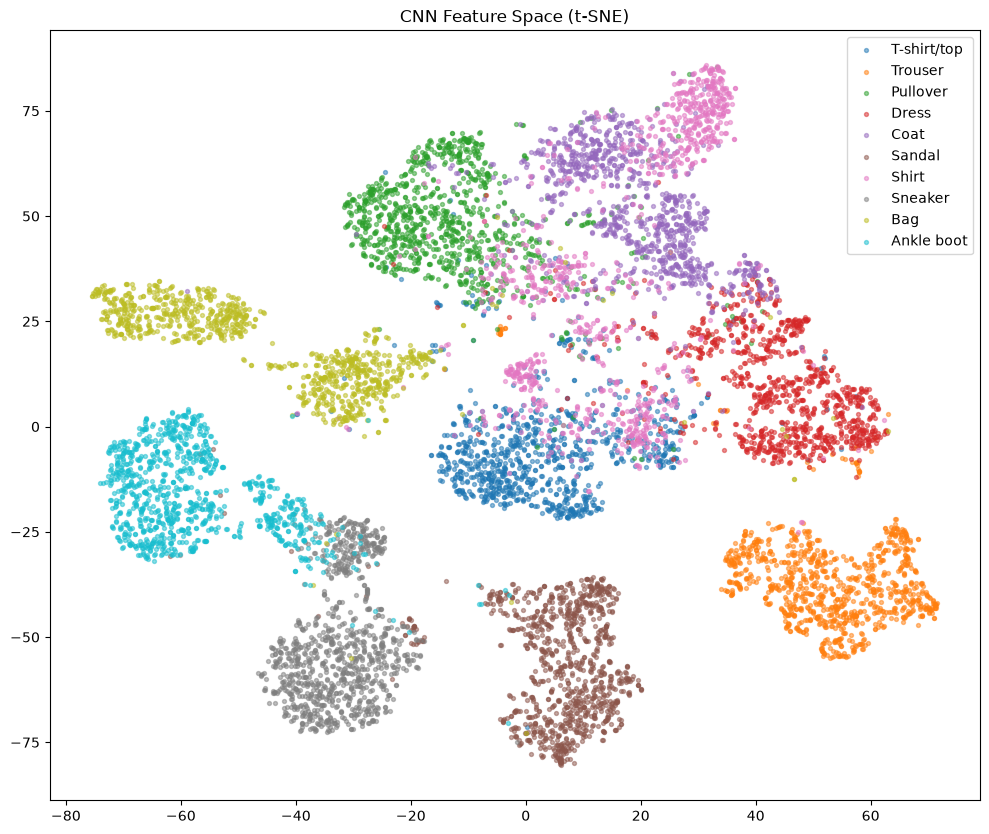

In [59]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

features_2d = tsne.fit_transform(features)

plt.figure(figsize=(12, 10))

for idx, class_name in enumerate(test_DS.classes):

    mask = labels == idx

    plt.scatter(
        features_2d[mask, 0],
        features_2d[mask, 1],
        label=class_name,
        s=8,
        alpha=0.5
    )

plt.legend()
plt.title('CNN Feature Space (t-SNE)')
plt.show()